# Fields & Qubits
## A Quantum Challenge in Digital Agriculture

Reconstruct binary water-stress maps for a 2 × 3 field observed on two dates.

- **Inputs:** observation scores, missing-data indicators, and spatial and temporal relationships.
- **Output:** one label per cell and date: 0 = not stressed, 1 = stressed.
- **Additional constraint:** exactly 3 stressed cells on Date 1 and 4 on Date 2.

We will build the model, check its QUBO and Ising formulations, find exact
solutions, and optionally compare them with a quantum solver.

### How to use this notebook

Use the **Python (Agriculture and Quantum)** kernel and keep the handout available offline.
Work from top to bottom. Complete each `TODO`, remove its `NotImplementedError`
line, and run the checks that follow. Running all cells before completing the
TODOs intentionally stops at the first unfinished task.
After completing the required tasks, restart the kernel and run those cells in order.
The quantum comparison is optional; the required work ends after the map plots.
Tasks 1–5 implement the corresponding handout problems. Task 6 and the optional
comparison implement Problem 6. Code marked **supplied** may be used unchanged.


In [1]:
# Numerical calculations and enumeration
import numpy as np
from itertools import product

# Graph algorithms and plotting
import networkx as nx
import matplotlib.pyplot as plt

# Display arrays clearly
np.set_printoptions(precision=3, suppress=True)

print("Setup complete.")

Setup complete.


## Supplied data

Run the next cell without changing the inputs.

- `R[t, i, j]`: evidence score from 0 to 10; larger scores support stress.
- `np.nan`: missing observation.
- `C[t, i, j]`: 1 if observed, 0 if missing.
- `w_spatial`, `w_temporal`: costs of disagreement between linked labels.
- `K[t]`: required number of stressed cells on date `t`, used in the count-constrained problem.
- `A`: count-penalty weight, used later.

Python indices start at **0**: `R[0]` is Date 1.
Scores are evidence, not the binary labels you will infer.

In [2]:
# Dimensions: rows, columns, dates
r, c, T = 2, 3, 2
N = r * c * T

# R[t, i, j]: evidence score at date t, row i, column j.
# Python indices start at 0. np.nan marks a missing observation.
R = np.array([
    [[9, 8, 2],
     [7, np.nan, 1]],

    [[8, 6, 3],
     [7, 4, np.nan]]
], dtype=float)

# C[t, i, j]: 1 = observed, 0 = missing.
C = np.array([
    [[1, 1, 1],
     [1, 0, 1]],

    [[1, 1, 1],
     [1, 1, 0]]
], dtype=int)

# Disagreement weights
w_spatial = 2
w_temporal = 1

# Survey counts and penalty weight (used later)
K = np.array([3, 4], dtype=int)
A = 4

assert R.shape == C.shape == (T, r, c)
assert np.array_equal(np.isnan(R), C == 0)
assert np.all((R[C == 1] >= 0) & (R[C == 1] <= 10))

print(f"{N} binary variables; {np.sum(C == 0)} missing observations.")

12 binary variables; 2 missing observations.


## Task 1: Build the space–time graph

Represent each cell on each date by one vertex.

Using zero-based Python indices, its ID is
$$
k = (rc)t + ci + j.
$$

Construct two lists of unordered edges `(u, v)`:

- `spatial_edges`: cells sharing a side on the same date.
- `temporal_edges`: the same cell on consecutive dates.

Include each edge once, with `u < v`. Do not include diagonal neighbours.

**Hint:** From each cell, consider only its right neighbour, the cell
in the next row, and the same cell on the next date, when they exist.

In [3]:
# Supplied helper: zero-based (row, column, date) -> vertex ID.
def vertex_id(i, j, t):
    return r * c * t + c * i + j


def build_edges():
    """Return spatial_edges and temporal_edges as lists of (u, v)."""
    spatial_edges = []
    temporal_edges = []

    for k in range(T):
        for i in range(r):
            for j in range(c):
                id_now = vertex_id(i, j, k)
                id_next = vertex_id(i, j + 1, k)
                if id_now > id_next:
                    continue

                # 0 -> 1, 1 -> 2, etc
                if id_next % 3 != 0:
                    side_neighbor = (id_now, id_next)
                    spatial_edges.append(side_neighbor)

                # 0 -> 3, 1 -> 4, etc
                if id_now % 6 < 3:
                    front_neighbor = (id_now, id_now + 3)
                    spatial_edges.append(front_neighbor)

                # 0 -> 6, 3 -> 9, etc
                if k == 0:
                    top_neighbor = (id_now, vertex_id(i, j, k + 1))
                    temporal_edges.append(top_neighbor)

    return spatial_edges, temporal_edges


spatial_edges, temporal_edges = build_edges()
print("Spatial edges:", len(spatial_edges))
print("Temporal edges:", len(temporal_edges))

Spatial edges: 14
Temporal edges: 6


In [4]:
# Run after completing build_edges().
# Expected counts come from Task 1 in the handout.
assert len(spatial_edges) == T * ((r - 1) * c + r * (c - 1))
assert len(temporal_edges) == (T - 1) * r * c

for edges in (spatial_edges, temporal_edges):
    assert len(edges) == len(set(edges)), "Duplicate edges found."
    assert all(0 <= u < v < N for u, v in edges), "Invalid vertex IDs or order."

# Decode IDs into (date, row, column) to check each relationship.
for u, v in spatial_edges:
    t1, i1, j1 = np.unravel_index(u, (T, r, c))
    t2, i2, j2 = np.unravel_index(v, (T, r, c))
    assert t1 == t2 and abs(i1 - i2) + abs(j1 - j2) == 1, (
        f"Invalid spatial edge: {(u, v)}"
    )

for u, v in temporal_edges:
    t1, i1, j1 = np.unravel_index(u, (T, r, c))
    t2, i2, j2 = np.unravel_index(v, (T, r, c))
    assert i1 == i2 and j1 == j2 and abs(t1 - t2) == 1, (
        f"Invalid temporal edge: {(u, v)}"
    )

print("Graph checks passed.")

Graph checks passed.


## Task 2: Build the reconstruction objective

Let `x[k]` be the label at vertex `k`: 0 = not stressed, 1 = stressed.

For an observed vertex with score $R_k$, the observation costs are
$$
D_k(0)=R_k,\qquad D_k(1)=10-R_k.
$$
For a missing observation, both costs are zero.

Implement:

1. `observation_cost(k, label)`: the cost of one label.
2. `energy_base(x)`: the sum of observation costs and disagreement costs.

A disagreement costs `w_spatial` on a spatial edge and `w_temporal`
on a temporal edge. Count each edge once.

**Hints:**
- `R.ravel()` and `C.ravel()` arrange the inputs in vertex-ID order.
- Check whether the observation is missing **before** using its score.
  Multiplying `np.nan` by zero still gives `np.nan`.
- Use your disagreement formula from Problem 2 of the handout.

In [7]:
# Supplied: observations arranged in vertex-ID order.
R_flat = R.ravel()
C_flat = C.ravel()
w_spatial, w_temporal = 2, 1

def observation_cost(k, label):
    """Return D_k(label), where label is 0 or 1."""
    if C_flat[k] == 0:
        return 0
    return R_flat[k] if label == 0 else 10 - R_flat[k]

def energy_base(x):
    """Return E_0(x) for a binary labeling of length N."""
    x = np.asarray(x, dtype=int)

    total_obs_cost = 0
    for i in range(x.shape[0]):
        total_obs_cost += observation_cost(i, x[i])

    # Compute the total edge disagreement cost
    total_dis_cost = 0
    for edge in spatial_edges:
        if x[edge[0]] != x[edge[1]]:
            total_dis_cost += w_spatial

    for edge in temporal_edges:
        if x[edge[0]] != x[edge[1]]:
            total_dis_cost += w_temporal

    return total_obs_cost + total_dis_cost

In [8]:
# Run after completing observation_cost() and energy_base().

# Vertex 0 has score 9.
assert observation_cost(0, 0) == 9
assert observation_cost(0, 1) == 1

# Missing observations contribute zero for either label.
for k in np.flatnonzero(C_flat == 0):
    assert observation_cost(k, 0) == 0
    assert observation_cost(k, 1) == 0

# Uniform labels have no disagreements, so only observation costs remain.
x_zeros = np.zeros(N, dtype=int)
x_ones = np.ones(N, dtype=int)
observed_scores = R_flat[C_flat == 1]

assert np.isclose(energy_base(x_zeros), observed_scores.sum())
assert np.isclose(energy_base(x_ones), (10 - observed_scores).sum())

print("Observation and uniform-label checks passed.")
# Nonuniform labels: flipping one cell creates disagreements on all its links.
# This checks disagreement costs independently of the QUBO coefficients.
for k in range(N):
    t, i, j = np.unravel_index(k, (T, r, c))
    spatial_neighbours = int(i > 0) + int(i + 1 < r) + int(j > 0) + int(j + 1 < c)
    temporal_neighbours = int(t > 0) + int(t + 1 < T)
    x_single = np.zeros(N, dtype=int)
    x_single[k] = 1
    observation_change = 0 if C_flat[k] == 0 else 10 - 2 * R_flat[k]
    expected_cost = (observed_scores.sum() + observation_change
                     + w_spatial * spatial_neighbours
                     + w_temporal * temporal_neighbours)
    assert np.isclose(energy_base(x_single), expected_cost, atol=1e-9, rtol=0), (
        f"Incorrect single-cell flip cost at vertex {k}."
    )
print("Single-cell disagreement checks passed.")


Observation and uniform-label checks passed.
Single-cell disagreement checks passed.


## Task 3: QUBO and Ising formulations

Use your derivations from Problem 3 to implement the coefficients.

For each vertex, define
$$
a_v=D_v(1)-D_v(0),\qquad d_v=\sum_u w_{uv}.
$$

Construct:

1. A constant `c0` and symmetric matrix `Q` such that
   $$
   E_0(x)=c_0+x^\top Qx.
   $$

2. A constant `cI`, vector `h`, and symmetric matrix `J` such that
   $$
   E_{\mathrm I}(z)
   =c_I+\sum_v h_vz_v+\sum_{u<v}J_{uv}z_uz_v,
   \qquad z=1-2x.
   $$

**Conventions and hints:**
- All vectors and matrix rows/columns follow vertex-ID order.
- Set `J[v, v] = 0`.
- In `x @ Q @ x`, each off-diagonal entry contributes twice because `Q` is symmetric.
- For the Ising pair sum, use only entries with `u < v`.
- Include both constant terms when comparing energies.
- Obtain observation costs through `observation_cost`; do not use missing scores directly.

In [9]:
def build_qubo():
    """Return c0 and symmetric Q, with E_0(x) = c0 + x @ Q @ x."""
    # Supplied: observation costs and their differences.
    D0 = np.array([observation_cost(k, 0) for k in range(N)])
    D1 = np.array([observation_cost(k, 1) for k in range(N)])
    a = D1 - D0

    Q = np.zeros((N, N), dtype=float)
    c0 = np.sum(R_flat[C_flat > 0])

    for k in range(N):
        spatial_neighbors = list(filter(lambda x: x[0] == k or x[1] == k, spatial_edges))
        temporal_neighbors = list(filter(lambda x: x[0] == k or x[1] == k, temporal_edges))
        d_k = len(spatial_neighbors) * w_spatial + len(temporal_neighbors) * w_temporal
        Q[k, k] = a[k] + d_k

        for n in spatial_neighbors:
            neighbor = n[1] if n[0] == k else n[0]
            Q[k, neighbor] = -w_spatial

        for n in temporal_neighbors:
            neighbor = n[1] if n[0] == k else n[0]
            Q[k, neighbor] = -w_temporal

    return c0, Q


def build_ising():
    """Return cI, h, and symmetric J; J has a zero diagonal."""
    D0 = np.array([observation_cost(k, 0) for k in range(N)])
    D1 = np.array([observation_cost(k, 1) for k in range(N)])
    a = D1 - D0

    h = np.zeros(N, dtype=float)
    J = np.zeros((N, N), dtype=float)

    # Found by replacing x_v with (1 - z_v) and simplifying the cost function
    cI = np.count_nonzero(C_flat > 0) * 5 + \
         len(spatial_edges) * 0.5 * w_spatial + \
         len(temporal_edges) * 0.5 * w_temporal

    h = -a / 2

    for k in range(N):
        spatial_neighbors = list(filter(lambda x: x[0] == k or x[1] == k, spatial_edges))
        temporal_neighbors = list(filter(lambda x: x[0] == k or x[1] == k, temporal_edges))

        for n in spatial_neighbors:
            neighbor = n[1] if n[0] == k else n[0]
            J[k, neighbor] = -w_spatial / 2

        for n in temporal_neighbors:
            neighbor = n[1] if n[0] == k else n[0]
            J[k, neighbor] = -w_temporal / 2

    return cI, h, J


c0, Q = build_qubo()
cI, h, J = build_ising()

In [10]:
# Supplied energy evaluators.
def energy_qubo(x):
    return c0 + x @ Q @ x


def energy_ising(z):
    # Use each unordered pair once.
    pair_cost = sum(
        J[u, v] * z[u] * z[v]
        for u in range(N)
        for v in range(u + 1, N)
    )
    return cI + h @ z + pair_cost


# Check shapes and symmetry.
assert Q.shape == J.shape == (N, N)
assert h.shape == (N,)
assert np.allclose(Q, Q.T)
assert np.allclose(J, J.T)
assert np.allclose(np.diag(J), 0)

# Generate all labelings; column k corresponds to vertex ID k.
all_x = np.array(list(product([0, 1], repeat=N)), dtype=int)

base_energies = np.array([energy_base(x) for x in all_x])
qubo_energies = np.array([energy_qubo(x) for x in all_x])
ising_energies = np.array([energy_ising(1 - 2*x) for x in all_x])

assert np.allclose(
    base_energies, qubo_energies, atol=1e-9, rtol=0
), "QUBO energies disagree with E_0."

assert np.allclose(
    base_energies, ising_energies, atol=1e-9, rtol=0
), "Ising energies disagree with E_0."

print(f"All three formulations agree for all {len(all_x)} labelings.")

All three formulations agree for all 4096 labelings.


## Task 4: Solve the base problem by minimum cut

Use your network construction from Problem 4 of the handout.

Add two terminals, `"source"` and `"sink"`, to the field vertices.
For a labeling $x$, the source side is
$$
S_x=\{\text{source}\}\cup\{v:x_v=1\}.
$$

Implement a directed network whose cut capacity equals $E_0(x)$:

1. Add an arc from the source to each field vertex.
2. Add an arc from each field vertex to the sink.
3. For each field edge `{u, v}`, add both arcs `(u, v)` and `(v, u)`.
4. Assign capacities using your derivation.

Then compute a minimum cut and convert its partition into binary labels:
source-side vertices receive 1; sink-side vertices receive 0.

**Hints:**
- Use `nx.DiGraph()`.
- Add an arc with `network.add_edge(u, v, capacity=value)`.
- `nx.minimum_cut(network, "source", "sink")` returns
  `(cut_value, (source_side, sink_side))`.
- Missing observations have zero observation costs; retain their vertices.
- This network solves $E_0$, without the survey-count constraints.

In [12]:
# Solve the problem classically so we have a known baseline
def build_cut_network():
    """Return a directed network whose cut capacity equals E_0(x)."""
    network = nx.DiGraph()
    network.add_nodes_from(range(N))
    network.add_nodes_from(["source", "sink"])

    for v in range(N):
        network.add_edge("source", v, capacity=observation_cost(v, 0))
        network.add_edge(v, "sink", capacity=observation_cost(v, 1))

    for (s, t) in spatial_edges:
        network.add_edge(s, t, capacity=w_spatial)
        network.add_edge(t, s, capacity=w_spatial)

    for (s, t) in temporal_edges:
        network.add_edge(s, t, capacity=w_temporal)
        network.add_edge(t, s, capacity=w_temporal)

    return network


network = build_cut_network()

# Supplied: compute a minimum cut.
cut_value, (source_side, sink_side) = nx.minimum_cut(
    network, "source", "sink", capacity="capacity"
)

# Convert the partition to a binary array x_cut of length N.
# Recall that field vertices on the source side receive label 1.
x_cut = np.array([1 if v in source_side else 0 for v in range(N)])

# Compare with direct evaluation and exhaustive enumeration.
assert np.isclose(cut_value, energy_base(x_cut), atol=1e-9, rtol=0)
assert np.isclose(cut_value, base_energies.min(), atol=1e-9, rtol=0)

print("Minimum-cut checks passed.")
print("Minimum cost:", cut_value)
print("Date maps:\n", x_cut.reshape(T, r, c))

Minimum-cut checks passed.
Minimum cost: 35.0
Date maps:
 [[[1 1 0]
  [1 1 0]]

 [[1 1 0]
  [1 1 0]]]


## Task 5: Add the survey counts

Now require exactly `K[0] = 3` stressed cells on Date 1
and `K[1] = 4` on Date 2.

Implement the penalty
$$
P_K(x)=\sum_{t=1}^{T}
\left(\sum_{v\in V_t}x_v-K_t\right)^2
$$
and the penalized objective
$$
E_A(x)=E_0(x)+A P_K(x),\qquad A=4.
$$

Using your expansion from Problem 5, construct `cA` and a symmetric
matrix `QA` such that
$$
E_A(x)=c_A+x^\top Q_Ax.
$$

**Hints:**
- `x.reshape(T, r*c).sum(axis=1)` gives the stressed-cell count on each date.
- Start with `QA = Q.copy()` so the original matrix remains unchanged.
- Update the constant, diagonal entries, and off-diagonal entries.
- The count penalty involves every pair of distinct vertices on the same date,
  whether or not they are spatial neighbours.
- Remember the factor of two for off-diagonal entries in a symmetric matrix.

You will verify that the direct and matrix expressions agree for all
4,096 labelings and that every minimizer satisfies both counts.

In [15]:
# Introduce an additional constraint: on each day there has to be a certain
# number of stressed cells. The added penalty is zero if and only if the stress
# counts for each day are correct.
K = np.array([3, 4])
A = 4 # Penalty weight

def count_penalty(x):
    """Return P_K(x): the sum of squared count errors."""
    counts = np.asarray(x).reshape(T, -1).sum(axis=1)
    return ((counts - K) ** 2).sum()

def energy_penalized(x):
    """Return E_A(x) using the direct penalty expression."""
    return energy_base(x) + A * count_penalty(x)


def build_penalized_qubo():
    """Return cA and symmetric QA for E_A(x) = cA + x @ QA @ x."""
    QA = Q.copy()
    cA = c0 + A * (K ** 2).sum()
    date_cells = N // T

    for t in range(T):
        date_ids = range(t * date_cells, (t + 1) * date_cells)
        for k in date_ids:
            QA[k, k] += A * (1 - 2 * K[t])
            # Each entry gets A in a same-date pair
            for j in date_ids:
                if j != k:
                    QA[k, j] += A

    return cA, QA


cA, QA = build_penalized_qubo()

In [16]:
# Supplied: independently calculate counts and feasibility.
counts = all_x.reshape(-1, T, r * c).sum(axis=2)
feasible = np.all(counts == K, axis=1)
expected_penalties = ((counts - K) ** 2).sum(axis=1)

penalties = np.array([count_penalty(x) for x in all_x])

assert np.allclose(penalties, expected_penalties, atol=1e-9, rtol=0), (
    "Count penalties are incorrect."
)

assert QA.shape == (N, N)
assert np.allclose(QA, QA.T), "QA must be symmetric."

penalized_energies = np.array([energy_penalized(x) for x in all_x])
penalized_qubo_energies = np.array([cA + x @ QA @ x for x in all_x])

assert np.allclose(
    penalized_energies, penalized_qubo_energies, atol=1e-9, rtol=0
), "The penalized QUBO disagrees with the direct expression."

# Check every minimizing assignment, including ties.
is_penalized_minimum = np.isclose(
    penalized_energies, penalized_energies.min(), atol=1e-9, rtol=0
)
assert np.all(feasible[is_penalized_minimum]), (
    "At least one penalized minimizer violates the counts."
)

print(f"Penalty checks passed for all {len(all_x)} labelings.")
print("Every penalized minimizer satisfies both counts.")

Penalty checks passed for all 4096 labelings.
Every penalized minimizer satisfies both counts.


## Task 6: Compare and visualize the exact solutions

Use the arrays calculated above:

- `all_x`: every binary labeling.
- `base_energies`: its cost under $E_0$.
- `feasible`: whether it satisfies both survey counts.
- `penalized_energies`: its cost under $E_A$.

Find and report:

1. The minimum of $E_0$ over all labelings and all assignments attaining it.
2. The number of feasible labelings.
3. The minimum of $E_0$ over feasible labelings and all assignments attaining it.
4. Whether each minimum is unique.
5. Which cell labels change between the two solutions, if both are unique.

Plot the date maps for the unconstrained and count-constrained solutions.

**Hints:**
- Use Boolean indexing to select feasible labelings and their energies.
- Use `np.isclose(..., atol=1e-9, rtol=0)` to identify all minimizers.
- `x.reshape(T, r, c)` converts a labeling into its date maps.
- Report $E_0$ for both solutions so their costs are directly comparable.

In [58]:
# Find the minimum base energy and all labelings attaining it.
min_cost = np.min(base_energies)
E_base_star = np.where(base_energies == min_cost)[0]
base_minimizers = all_x[E_base_star]

n_feasible = np.sum(feasible == True) # Count feasible labelings.

# Find the minimum base energy among feasible labelings and all feasible labelings attaining it.
penalized_min_cost = np.min(penalized_energies)
E_K_star = np.where(penalized_energies == penalized_min_cost)[0]
count_minimizers = all_x[E_K_star]

print("Unconstrained minimum:", E_base_star)
print("Number of unconstrained minimizers:", len(base_minimizers))
print("Feasible labelings:", n_feasible)
print("Count-constrained minimum:", E_K_star)
print("Number of count-constrained minimizers:", len(count_minimizers))

if len(base_minimizers) == len(count_minimizers) == 1:
    x_base = base_minimizers[0]
    x_count = count_minimizers[0]

    changed_ids = np.flatnonzero(x_base != x_count)
    print("Changed vertex IDs:", changed_ids)

    for k in changed_ids:
        t, i, j = np.unravel_index(k, (T, r, c))
        print(f"Date {t + 1}, row {i + 1}, column {j + 1}")

[3382]
Unconstrained minimum: [3510]
Number of unconstrained minimizers: 1
Feasible labelings: 300
Count-constrained minimum: [3382]
Number of count-constrained minimizers: 1
Changed vertex IDs: [4]
Date 1, row 2, column 2


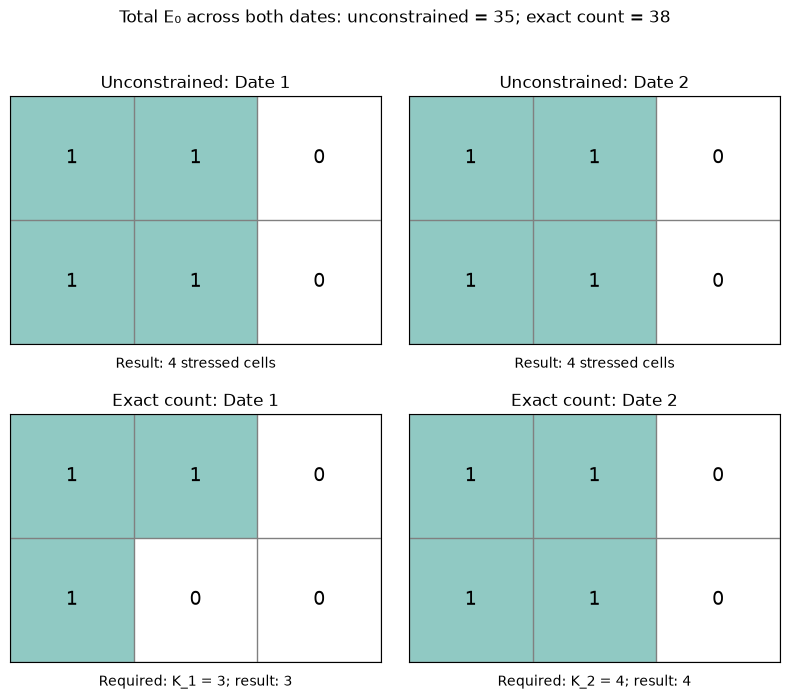

In [32]:
from matplotlib.colors import ListedColormap


def plot_comparison(x_base, x_count):
    """Plot one unconstrained and one count-constrained solution."""
    cmap = ListedColormap(["white", "#90c9c3"])
    fig, axes = plt.subplots(2, T, figsize=(4 * T, 7), squeeze=False)

    for row, x in enumerate((x_base, x_count)):
        maps = np.asarray(x).reshape(T, r, c)

        for t in range(T):
            ax = axes[row, t]
            ax.imshow(maps[t], cmap=cmap, vmin=0, vmax=1)

            for i in range(r):
                for j in range(c):
                    ax.text(j, i, str(maps[t, i, j]),
                            ha="center", va="center", fontsize=14)

            case = "Unconstrained" if row == 0 else "Exact count"
            count = int(maps[t].sum())
            ax.set_title(f"{case}: Date {t + 1}")
            ax.set_xlabel(
                f"Result: {count} stressed cells" if row == 0
                else f"Required: K_{t + 1} = {K[t]}; result: {count}"
            )

            ax.set_xticks([])
            ax.set_yticks([])
            ax.set_xticks(np.arange(-0.5, c, 1), minor=True)
            ax.set_yticks(np.arange(-0.5, r, 1), minor=True)
            ax.grid(which="minor", color="gray", linewidth=1)
            ax.tick_params(which="minor", bottom=False, left=False)

    fig.suptitle(
        f"Total E₀ across both dates: unconstrained = {energy_base(x_base):g}; "
        f"exact count = {energy_base(x_count):g}"
    )
    fig.tight_layout(h_pad=3.0, w_pad=2.0, rect=(0, 0, 1, 0.95))
    plt.show()


# Plot the first minimizer from each set.
# If either set contains several minimizers, this shows one example.
plot_comparison(base_minimizers[0], count_minimizers[0])

## Optional quantum comparison (Problem 6, Part 3)

Use the penalized objective $E_A$ with $A=4$, represented by `cA` and `QA`.

We will supply a small QAOA example running on a local simulator.
QAOA uses a parameterized quantum circuit and a classical optimizer
to search for low-cost labelings. You do not need to derive the circuit.

Your tasks are to:

1. Run the supplied example.
2. Check the returned labelings against both survey counts.
3. Report the feasible fraction, best feasible cost under $E_0$,
   and its gap from `E_K_star`.

The exact answers from Task 6 provide the reference.
The quantum solver is not guaranteed to find an optimum.

**Important:**
- Use the penalized coefficients `cA, QA`, not the base coefficients `c0, Q`.
- Count repeated samples when calculating the feasible fraction.
- If no sample is feasible, report the best feasible cost and gap as unavailable.
- Hardware access is not required.

In [37]:
from qiskit_optimization import QuadraticProgram


# Create binary variables in vertex-ID order.
quantum_problem = QuadraticProgram("Fields_and_Qubits")
for k in range(N):
    quantum_problem.binary_var(name=f"x{k}")

# For binary variables, QA[k, k] * x[k]**2 = QA[k, k] * x[k].
linear = {f"x{k}": float(QA[k, k]) for k in range(N)}

# Combine the two symmetric matrix entries into one pair coefficient.
quadratic = {
    (f"x{u}", f"x{v}"): float(QA[u, v] + QA[v, u])
    for u in range(N)
    for v in range(u + 1, N)
    if QA[u, v] + QA[v, u] != 0
}

quantum_problem.minimize(
    constant=float(cA),
    linear=linear,
    quadratic=quadratic
)

# Counts are already encoded in the penalty: do not add them again.
qiskit_energies = np.array([
    quantum_problem.objective.evaluate(x) for x in all_x
])

assert np.allclose(
    qiskit_energies, penalized_energies, atol=1e-9, rtol=0
), "Qiskit's objective disagrees with E_A."

print(f"Qiskit conversion verified for all {len(all_x)} labelings.")
print("Binary variables:", quantum_problem.get_num_binary_vars())

Qiskit conversion verified for all 4096 labelings.
Binary variables: 12


In [36]:
from qiskit.primitives import StatevectorSampler
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_algorithms import QAOA
from qiskit_algorithms.optimizers import COBYLA

# Convert the penalized objective to an Ising operator.
# E_A(x) = <x|cost_operator|x> + energy_offset.
cost_operator, energy_offset = quantum_problem.to_ising()

# Experiment settings: record these with your results.
seed = 42
shots = 1024                 # Samples per circuit evaluation
reps = 1                     # Number of QAOA layers
maxiter = 60                  # Classical optimization budget

sampler = StatevectorSampler(default_shots=shots, seed=seed)
optimizer = COBYLA(maxiter=maxiter)

# Supplied: compile evolution gates into elementary gates before simulation.
# This avoids constructing large evolution matrices in StatevectorSampler.
pass_manager = generate_preset_pass_manager(
    optimization_level=1,
    basis_gates=["h", "rx", "ry", "rz", "cx"],
    seed_transpiler=seed
)

qaoa = QAOA(
    sampler=sampler,
    optimizer=optimizer,
    reps=reps,
    transpiler=pass_manager,
    initial_point=np.full(2 * reps, 0.5)  # Two parameters per layer
)

print("Running QAOA on the local simulator...")
qaoa_result = qaoa.compute_minimum_eigenvalue(cost_operator)

estimated_mean_cost = float(
    np.real(qaoa_result.eigenvalue) + energy_offset
)

print("Optimization finished.")
print("Estimated mean penalized cost:", estimated_mean_cost)

# This is an estimated average cost, not the best sampled labeling.
# Next, we will sample the optimized circuit and assess its outputs.

Running QAOA on the local simulator...
Optimization finished.
Estimated mean penalized cost: 81.251953125


In [38]:
# Supplied: bind the optimized parameters.
optimized_circuit = qaoa_result.optimal_circuit.assign_parameters(
    qaoa_result.optimal_parameters
)

# Measure qubit k into classical bit k.
optimized_circuit = optimized_circuit.remove_final_measurements(inplace=False)
optimized_circuit.measure_all()

# Collect fresh samples for the comparison.
final_shots = 4096
evaluation_seed = 123
evaluation_sampler = StatevectorSampler(seed=evaluation_seed)

sample_result = evaluation_sampler.run(
    [optimized_circuit], shots=final_shots
).result()[0]

bitstrings = sample_result.data.meas.get_bitstrings()

# Qiskit displays qubit 0 on the RIGHT.
# Reverse each string so column k matches vertex ID k.
quantum_samples = np.array([
    [int(bit) for bit in bits[::-1]]
    for bits in bitstrings
], dtype=int)

# Each row is one measurement; retain repeated labelings.
assert quantum_samples.shape == (final_shots, N)
assert np.all((quantum_samples == 0) | (quantum_samples == 1))

print("Samples collected:", len(quantum_samples))
print("Distinct labelings:", len(np.unique(quantum_samples, axis=0)))

Samples collected: 4096
Distinct labelings: 1777


In [65]:
L = len(quantum_samples)

# Count how many quantum samples match the specific requirement set by K
sample_counts = quantum_samples.reshape(L, T, r*c).sum(axis=-1)
sample_feasible = (sample_counts == K).all(axis=1)

# Calculate the fraction of samples that are feasible.
feasible_fraction = sample_feasible.sum() / L

if np.any(sample_feasible):
    # Evaluate E_0 on each feasible sample.
    # Find the smallest cost and subtract E_K_star.

    E_best = float("inf")
    classical_best = energy_qubo(all_x[E_K_star][0])

    for i in range(L):
        if not sample_feasible[i]:
            continue
        cost = energy_qubo(quantum_samples[i])
        E_best = min(E_best, cost)

    gap = classical_best - E_best
    print("Best feasible base cost:", E_best)
    print("Optimality gap:", gap)
else:
    E_best = None
    gap = None
    print("Best feasible base cost: unavailable")
    print("Optimality gap: unavailable")

print("Feasible fraction:", feasible_fraction)
print("Samples:", L)
print("Solver: QAOA")
print("Simulator: StatevectorSampler")
print("Layers:", reps)
print("Optimization budget:", maxiter)
print("Shots per circuit evaluation:", shots)
print("Optimization seed:", seed)
print("Evaluation seed:", evaluation_seed)

Best feasible base cost: 38.0
Optimality gap: 0.0
Feasible fraction: 0.083740234375
Samples: 4096
Solver: QAOA
Simulator: StatevectorSampler
Layers: 1
Optimization budget: 60
Shots per circuit evaluation: 1024
Optimization seed: 42
Evaluation seed: 123


## Report your results

Include:

- The exact unconstrained and count-constrained minimum costs.
- The number of minimizers in each case and the number of feasible labelings.
- The four optimal date maps.
- Confirmation that all energy formulations agree for every labeling.
- Confirmation that every penalized minimizer satisfies both counts.

If you completed the optional quantum experiment, also report:

- Solver, simulator, settings, and number of evaluation samples.
- Feasible fraction, best feasible base cost, and optimality gap.
- Whether an exact constrained optimum was found among the samples.

**Interpretation:** These results measure how well the code solves the
supplied optimization problem. Prediction accuracy would require
ground-reference stress labels. This experiment does not establish
a quantum advantage.